# Week 9 실습 — LLM Generation과 Decoding
**대형언어모델 · 오프라인 실습 (10/27)**


- 기본 모델: `Qwen/Qwen3-0.6B` (GPU 권장, CPU도 가능 — `QUICK=1` 환경변수로 실험 규모 축소)
- `# TODO` 셀을 채우고, 바로 아래의 **검증 셀**이 통과하는지 확인하세요.
- 참고: Holtzman et al. (ICLR 2020), Fan et al. (ACL 2018), Nguyen et al. (min-p, 2024), Chen et al. (pass@k, 2021)

## 0. Colab 준비
1. 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 선택 후 저장
2. 아래 셀을 실행한다 (패키지 설치 · 한글 글꼴 · GPU 확인). 설치 후 "세션 다시 시작" 안내가 나오면 따른 뒤 **다음 셀부터** 실행한다.
3. 결과(그래프 · 표)는 노트북에 남는다. **파일 → 드라이브에 사본 저장**으로 본인 드라이브에 저장해 제출한다.

In [1]:
# Colab 준비 셀 (로컬 Jupyter에서는 건너뛰어도 된다)
import sys, subprocess, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run("pip install -q -U 'transformers>=4.51' accelerate", shell=True)
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True)   # 그래프 한글 글꼴
    import matplotlib.font_manager as fm
    for f in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf"]:
        if os.path.exists(f):
            fm.fontManager.addfont(f)
import torch
print("Colab:", IN_COLAB, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음 (런타임 유형을 T4 GPU로 바꿀 것)")

Colab: True | GPU: Tesla T4


In [2]:
import os, time, math, random, re, json, itertools
from collections import Counter
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import font_manager
for _f in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK KR"]:   # 한글 글꼴 (있는 것 사용)
    if any(_f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False
from transformers import AutoTokenizer, AutoModelForCausalLM

QUICK = False        # True: 작은 규모로 빠르게 (수업 시간이 부족하면 True)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
MODEL_NAME = "Qwen/Qwen3-0.6B"
# T4(Colab 무료)는 bf16 연산이 느리므로 float32, bf16을 지원하는 GPU(A100 등)는 bf16
DTYPE = torch.bfloat16 if (DEVICE == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
print("device:", DEVICE, "| dtype:", DTYPE, "| QUICK:", QUICK, "| torch", torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def load_causal_lm(name):
    try:
        m = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE)           # transformers >= 4.56
    except TypeError:
        m = AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE)     # 이전 버전
    return m.to(DEVICE).eval()

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = load_causal_lm(MODEL_NAME)
eos = model.generation_config.eos_token_id
EOS_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
print("EOS ids:", EOS_IDS)

def encode_chat(prompt, think=False):
    text = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=think)
    return tok(text, return_tensors="pt").input_ids.to(DEVICE)

device: cuda | dtype: torch.bfloat16 | QUICK: False | torch 2.11.0+cu130


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'TypeError: Failed to fetch'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

EOS ids: {151643, 151645}


## Lab 1. Logits processor 직접 구현

모든 함수는 `z: [B, V]` logits를 받아 **변형된 logits**를 돌려준다 (제거할 token은 `-inf`).

| 함수 | 수식 |
|---|---|
| temperature | $z / T$ |
| top-k | 상위 $k$개 외 $-\infty$ |
| top-p | 누적 확률이 처음 $p$ 이상이 되는 최소 집합만 유지 |
| min-p | $p(v) < p_{base}\cdot \max_u p(u)$ 이면 제거 |
| repetition (CTRL/HF) | 이전 token $i$: $z_i>0$ 이면 $z_i/r$, 아니면 $z_i\cdot r$ |
| frequency · presence (OpenAI) | $z_j - c_j\alpha_{freq} - \mathbb{1}[c_j>0]\alpha_{pres}$ |

In [3]:
NEG_INF = float("-inf")

def apply_temperature(z, T):
    assert T > 0
    return z / T

def top_k_filter(z, k):
    if k is None or k <= 0:
        return z
    k = min(k, z.size(-1))
    v, _ = z.topk(k, dim=-1)
    return z.masked_fill(z < v[..., -1:], NEG_INF)

def top_p_filter(z, p):
    if p is None or p >= 1.0:
        return z
    s, idx = z.sort(dim=-1, descending=True)
    pr = s.softmax(-1)
    remove = (pr.cumsum(-1) - pr) >= p
    s = s.masked_fill(remove, NEG_INF)
    return torch.full_like(z, NEG_INF).scatter(-1, idx, s)

def min_p_filter(z, p_base):
    if not p_base:
        return z
    pr = z.softmax(-1)
    thr = p_base * pr.max(dim=-1, keepdim=True).values
    return z.masked_fill(pr < thr, NEG_INF)

def repetition_penalty(z, seen_ids, r):
    if r == 1.0 or seen_ids.numel() == 0:
        return z
    sc = z.gather(1, seen_ids)
    sc = torch.where(sc < 0, sc * r, sc / r)
    return z.scatter(1, seen_ids, sc)

def presence_frequency_penalty(z, gen_ids, alpha_freq=0.0, alpha_pres=0.0):
    if gen_ids.numel() == 0 or (alpha_freq == 0 and alpha_pres == 0):
        return z
    c = torch.zeros_like(z)
    c.scatter_add_(1, gen_ids, torch.ones_like(gen_ids, dtype=z.dtype))
    return z - c * alpha_freq - (c > 0).to(z.dtype) * alpha_pres

### 검증: HF 구현과 같은 집합을 남기는가
`transformers`의 `TopKLogitsWarper`, `TopPLogitsWarper`, `MinPLogitsWarper`, `RepetitionPenaltyLogitsProcessor`와 비교한다.

In [4]:
from transformers import (TopKLogitsWarper, TopPLogitsWarper, MinPLogitsWarper,
                          RepetitionPenaltyLogitsProcessor)
g = torch.Generator().manual_seed(0)
z = torch.randn(4, 500, generator=g) * 3
ids_dummy = torch.randint(0, 500, (4, 20), generator=g)

def same_mask(a, b):
    return torch.equal(torch.isinf(a), torch.isinf(b))

assert same_mask(top_k_filter(z, 20), TopKLogitsWarper(20)(ids_dummy, z.clone()))
for p in (0.5, 0.8, 0.95):
    assert same_mask(top_p_filter(z, p), TopPLogitsWarper(p)(ids_dummy, z.clone())), p
for mp in (0.05, 0.1, 0.3):
    assert same_mask(min_p_filter(z, mp), MinPLogitsWarper(mp)(ids_dummy, z.clone())), mp
assert torch.allclose(repetition_penalty(z, ids_dummy, 1.3),
                      RepetitionPenaltyLogitsProcessor(1.3)(ids_dummy, z.clone()))
c = presence_frequency_penalty(z[:1], torch.tensor([[3, 3, 7]]), 0.5, 1.0)
assert torch.isclose(z[0, 3] - c[0, 3], torch.tensor(2 * 0.5 + 1.0)) and torch.isclose(z[0, 7] - c[0, 7], torch.tensor(1.5))
print("Lab 1 검증 통과 ✓")

Lab 1 검증 통과 ✓


In [5]:
# 슬라이드의 temperature 예시 재현: logits [2.0, 1.0, 0.1]
zt = torch.tensor([[2.0, 1.0, 0.1]])
pd.DataFrame({f"T={T}": apply_temperature(zt, T).softmax(-1)[0].numpy().round(3) for T in (0.5, 1.0, 2.0)},
             index=["A", "B", "C"]).T

,A,B,C
T=0.5,0.864,0.117,0.019
T=1.0,0.659,0.242,0.099
T=2.0,0.502,0.304,0.194


In [6]:
# 실제 모델의 다음 token 분포에서 각 필터가 남기는 token 수 (문맥에 따라 top-p가 남기는 수가 변함)
prompts = ["대한민국의 수도는", "옛날 옛적 어느 마을에", "def fibonacci(n):"]
rows = []
with torch.no_grad():
    for q in prompts:
        ids = tok(q, return_tensors="pt").input_ids.to(DEVICE)
        zz = model(ids).logits[:, -1, :].float().cpu()
        H = -(zz.softmax(-1) * zz.log_softmax(-1)).sum().item()
        rows.append({"prompt": q, "entropy(nats)": round(H, 2),
                     "top-k=20": 20,
                     "top-p=0.9": int(torch.isfinite(top_p_filter(zz, 0.9)).sum()),
                     "min-p=0.1": int(torch.isfinite(min_p_filter(zz, 0.1)).sum())})
pd.DataFrame(rows)

,prompt,entropy(nats),top-k=20,top-p=0.9,min-p=0.1
0,대한민국의 수도는,5.06,20,189,36
1,옛날 옛적 어느 마을에,5.17,20,256,10
2,def fibonacci(n):,0.49,20,2,1


## Lab 2. KV cache를 쓰는 `generate()` 직접 구현

- 첫 forward: 프롬프트 전체 (prefill) → `past_key_values` 반환
- 이후: **새 token 1개**만 입력하고 cache 재사용 (decode)
- 순서: penalty → temperature → top-k → top-p → min-p → 샘플링 (슬라이드의 파이프라인)

In [7]:
@torch.no_grad()
def generate_manual(ids, max_new=64, T=1.0, k=None, p=None, min_p=None,
                    rep=1.0, freq=0.0, pres=0.0, greedy=False, seed=None):
    if seed is not None:
        set_seed(seed)
    P = ids.shape[1]
    out, x, past = ids, ids, None
    for _ in range(max_new):
        o = model(input_ids=x, past_key_values=past, use_cache=True)
        past, z = o.past_key_values, o.logits[:, -1, :].float()
        z = repetition_penalty(z, out, rep)                     # HF처럼 프롬프트 포함
        z = presence_frequency_penalty(z, out[:, P:], freq, pres)
        if greedy:
            nxt = z.argmax(-1, keepdim=True)
        else:
            z = apply_temperature(z, T)
            z = top_k_filter(z, k); z = top_p_filter(z, p); z = min_p_filter(z, min_p)
            nxt = torch.multinomial(z.softmax(-1), num_samples=1)
        out = torch.cat([out, nxt], dim=1)
        x = nxt
        if nxt.item() in EOS_IDS:
            break
    return out[:, P:]

ids = encode_chat("온디바이스 AI를 한 문단으로 설명해줘.")
mine = generate_manual(ids, max_new=48, greedy=True)
hf = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=48, do_sample=False)[:, ids.shape[1]:]
n = min(mine.shape[1], hf.shape[1])
print("greedy 일치:", torch.equal(mine[:, :n], hf[:, :n]), f"(비교 길이 {n})")
print(tok.decode(mine[0], skip_special_tokens=True))

greedy 일치: True (비교 길이 48)
온디바이스 AI는 인공지능 기술을 활용하여 다양한 분야에서 혁신적인 기술을 개발하고, 인간과 AI의 협업을 통해 효율적인 작업을 수행하는 기


> 불일치가 나면: (1) `generation_config`의 기본 processor(예: repetition_penalty, top_k)가 켜져 있는지, (2) dtype(bf16) 수치 차이, (3) EOS 목록을 확인한다.
> **KV cache 효과**: 아래 셀에서 `use_cache` on/off의 시간 차이를 측정한다 (10주차와 연결).

In [8]:
@torch.no_grad()
def time_generate(use_cache, n_new):
    ids = encode_chat("숫자를 1부터 계속 세어라.")
    t0 = time.perf_counter()
    model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=n_new, min_new_tokens=n_new,
                   do_sample=False, use_cache=use_cache)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return n_new / (time.perf_counter() - t0)

lens = [16, 32] if QUICK else [32, 64, 128, 256]
res = [{"n_new": n, "cache on (tok/s)": time_generate(True, n), "cache off (tok/s)": time_generate(False, n)} for n in lens]
df_cache = pd.DataFrame(res).round(1); df_cache

,n_new,cache on (tok/s),cache off (tok/s)
0,32,11.3,7.5
1,64,11.7,8.8
2,128,10.6,11.4
3,256,20.8,11.9


## Lab 3. Beam search와 Constrained decoding

### 3-1. Beam search (교육용, KV cache 없음)
점수는 $\sum \log p$ 이고, 최종 선택 시 길이 정규화 $\text{score}/|y|^{\alpha}$ (HF `length_penalty` 형태)를 적용한다.

In [9]:
@torch.no_grad()
def beam_search(ids, B=4, max_new=32, alpha=1.0):
    P = ids.shape[1]
    beams = [(ids, 0.0, False)]                        # (seq, sum log p, finished)
    for _ in range(max_new):
        cand = []
        for seq, lp, done in beams:
            if done:
                cand.append((seq, lp, True)); continue
            logp = model(seq).logits[:, -1].float().log_softmax(-1)
            top = logp.topk(B, dim=-1)
            for v, i in zip(top.values[0], top.indices[0]):
                nseq = torch.cat([seq, i.view(1, 1)], dim=1)
                cand.append((nseq, lp + v.item(), i.item() in EOS_IDS))
        beams = sorted(cand, key=lambda c: c[1], reverse=True)[:B]
        if all(d for _, _, d in beams):
            break
    norm = lambda c: c[1] / max(1, c[0].shape[1] - P) ** alpha
    best = max(beams, key=norm)
    return best[0][:, P:], best[1]

@torch.no_grad()
def seq_logprob(ids, gen):
    full = torch.cat([ids, gen], dim=1)
    lp = model(full).logits[:, :-1].float().log_softmax(-1)
    tgt = full[:, 1:]
    return lp.gather(-1, tgt.unsqueeze(-1)).squeeze(-1)[:, ids.shape[1] - 1:].sum().item()

ids = encode_chat("인공지능을 한 문장으로 정의하라.")
g_greedy = generate_manual(ids, max_new=24, greedy=True)
g_beam, _ = beam_search(ids, B=2 if QUICK else 4, max_new=24)
for name, g_ in [("greedy", g_greedy), ("beam", g_beam)]:
    print(f"{name:6s} logp={seq_logprob(ids, g_):8.2f} len={g_.shape[1]:3d} | {tok.decode(g_[0], skip_special_tokens=True)}")

greedy logp=  -11.64 len= 24 | 인공지능은 인간의 생각과 판단을 기반으로 한 자동화된 시스템입니다.
beam   logp=   -9.30 len= 24 | 인공지능은 인공지능을 한 문장으로 정의하면 다음과 같습니다: **인공지


### 3-2. Constrained decoding: 숫자만 출력하도록 강제
허용 token 집합 외의 logits를 $-\infty$로 만드는 `LogitsProcessor`. (형식은 보장하지만 **내용의 정확성은 보장하지 않는다**.)

In [10]:
from transformers import LogitsProcessor, LogitsProcessorList

class AllowedTokens(LogitsProcessor):
    def __init__(self, allowed_ids):
        self.allowed = torch.tensor(sorted(set(allowed_ids)))
    def __call__(self, input_ids, scores):
        mask = torch.full_like(scores, NEG_INF)
        mask[:, self.allowed.to(scores.device)] = 0
        return scores + mask

V = len(tok)
digit_ids = [i for i in range(V) if tok.decode([i]).strip().isdigit()]
allowed = digit_ids + list(EOS_IDS)
ids = encode_chat("37 더하기 48은 얼마인가? 숫자만 답하라.")
out = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=6, do_sample=False,
                     logits_processor=LogitsProcessorList([AllowedTokens(allowed)]))
ans = tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)
print("출력:", repr(ans)); assert re.fullmatch(r"\s*\d*\s*", ans), "숫자 외 문자가 나오면 안 된다"

출력: '3748'


## Lab 4. Decoding 설정 비교 실험

- 프롬프트: 열린 생성 + 정답형(덧셈 문제, 정답 자동 확인)
- 지표: **distinct-2**(샘플 간 다양성), **반복률**(샘플 내 중복 4-gram 비율), **루프율**(반복률 > 0.5), 평균 길이, **정답률**, tokens/s
- 같은 설정을 여러 seed로 반복해 평균 ± 표준편차로 보고한다

In [11]:
OPEN = ["온디바이스 AI의 장점을 설명하라.", "비 오는 날에 대한 짧은 이야기를 써라.", "좋은 연구 질문의 조건은?",
        "커피를 처음 마시는 사람에게 추천을 해줘.", "트랜스포머 attention을 비유로 설명하라.",
        "새 학기 계획을 세우는 방법은?", "도서관을 묘사하는 시를 써라.", "양자화가 필요한 이유는?",
        "여행 짐 싸기 요령을 알려줘.", "로봇이 주인공인 짧은 동화를 써라."]
rng = random.Random(0)
QA = []
for _ in range(10):
    a, b = rng.randint(10, 99), rng.randint(10, 99)
    QA.append((f"{a} 더하기 {b}는? 숫자만 답하라.", str(a + b)))

CONFIGS = {
    "greedy":            dict(greedy=True),
    "T0.3+top-p0.8":     dict(T=0.3, p=0.8),
    "T0.7+top-p0.8+k20": dict(T=0.7, p=0.8, k=20),       # Qwen3 non-thinking 권장
    "T1.0+top-p0.95":    dict(T=1.0, p=0.95),
    "T1.3+min-p0.1":     dict(T=1.3, min_p=0.1),
    "T1.3 (no trunc)":   dict(T=1.3),
    "T0.7+rep1.3":       dict(T=0.7, p=0.8, rep=1.3),
    "T0.7+pres1.0":      dict(T=0.7, p=0.8, pres=1.0),
}
SEEDS = [0] if QUICK else [0, 1, 2]
MAX_NEW = 24 if QUICK else 128
if QUICK:
    OPEN, QA = OPEN[:2], QA[:2]
    CONFIGS = dict(list(CONFIGS.items())[:3])

In [12]:
def distinct_n(token_lists, n=2):
    grams = [tuple(t[i:i + n]) for t in token_lists for i in range(len(t) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

def repeat_ratio(tokens, n=4):
    grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return 0.0 if not grams else 1 - len(set(grams)) / len(grams)

assert abs(distinct_n([[1, 2, 3], [1, 2, 4]], 2) - 3 / 4) < 1e-9
assert repeat_ratio([1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4], 4) > 0.5 and repeat_ratio(list(range(10))) == 0
print("지표 함수 검증 통과 ✓")

지표 함수 검증 통과 ✓


### 시간이 오래걸릴 수 있으므로, SEED 및 MAX_NEW를 줄여서 실험 권장

In [13]:
def last_number(s):
    m = re.findall(r"-?\d+", s.replace(",", ""))
    return m[-1] if m else None

records = []
for name, cfg in CONFIGS.items():
    for seed in SEEDS:
        gens, t_tok, t_sec, correct = [], 0, 0.0, []
        for q in OPEN:
            ids = encode_chat(q)
            t0 = time.perf_counter(); g_ = generate_manual(ids, max_new=MAX_NEW, seed=seed, **cfg)
            t_sec += time.perf_counter() - t0; t_tok += g_.shape[1]
            gens.append(g_[0].tolist())
        for q, a in QA:
            g_ = generate_manual(encode_chat(q), max_new=16, seed=seed, **cfg)
            correct.append(last_number(tok.decode(g_[0], skip_special_tokens=True)) == a)
        rr = [repeat_ratio(t) for t in gens]
        records.append({"config": name, "seed": seed, "distinct-2": distinct_n(gens, 2),
                        "repeat": np.mean(rr), "loop rate": np.mean([r > 0.5 for r in rr]),
                        "len": np.mean([len(t) for t in gens]), "acc": np.mean(correct), "tok/s": t_tok / t_sec})
df = pd.DataFrame(records)
summary = df.groupby("config").agg(["mean", "std"]).drop(columns="seed").round(3)
summary

distinct-2        repeat        loop rate             len  \
                        mean    std   mean    std      mean    std     mean   
config                                                                        
T0.3+top-p0.8          0.575  0.021  0.216  0.016     0.133  0.115  125.733   
T0.7+pres1.0           0.770  0.007  0.035  0.001     0.000  0.000  126.333   
T0.7+rep1.3            0.900  0.010  0.002  0.000     0.000  0.000  116.867   
T0.7+top-p0.8+k20      0.662  0.055  0.139  0.067     0.067  0.058  126.567   
T1.0+top-p0.95         0.820  0.006  0.028  0.003     0.000  0.000  122.367   
T1.3 (no trunc)        0.793  0.053  0.002  0.001     0.000  0.000  104.433   
T1.3+min-p0.1          0.768  0.010  0.046  0.015     0.000  0.000  125.133   
greedy                 0.600  0.000  0.198  0.000     0.200  0.000  125.600   

                            acc          tok/s         
                     std   mean    std    mean    std  
config                                                 
T0.3+top-p0.8      1.850  1.000  0.000  19.973  0.804  
T0.7+pres1.0       0.723  1.000  0.000  19.372  2.082  
T0.7+rep1.3        6.854  0.967  0.058  20.505  0.152  
T0.7+top-p0.8+k20  1.250  1.000  0.000  20.279  0.122  
T1.0+top-p0.95     5.552  1.000  0.000  20.475  0.087  
T1.3 (no trunc)    7.524  0.933  0.115  20.652  0.010  
T1.3+min-p0.1      4.210  1.000  0.000  20.620  0.133  
greedy             0.000  1.000  0.000  18.006  2.316

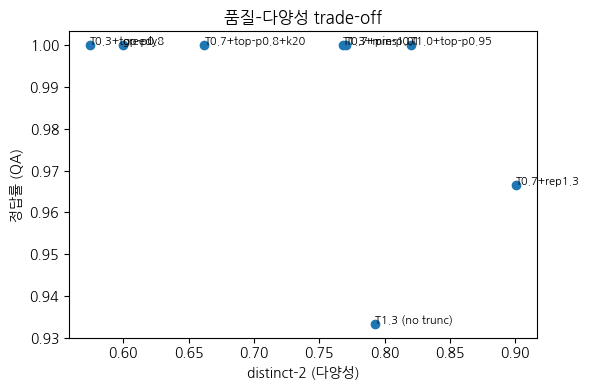

In [14]:
m = df.groupby("config").mean(numeric_only=True)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(m["distinct-2"], m["acc"])
for k_, r_ in m.iterrows():
    ax.annotate(k_, (r_["distinct-2"], r_["acc"]), fontsize=8)
ax.set_xlabel("distinct-2 (다양성)"); ax.set_ylabel("정답률 (QA)"); ax.set_title("품질–다양성 trade-off")
plt.tight_layout(); plt.show()

**분석 질문**
1. 어떤 설정이 루프율이 가장 높은가? 그 이유를 분포 관점(정점 · 꼬리)에서 설명하라.
2. `T1.3 (no trunc)`와 `T1.3+min-p0.1`의 차이는 무엇을 보여주는가?
3. 정답형 과제와 열린 생성에서 최적 설정이 같은가?

## Lab 5. Self-consistency와 pass@k

$$\text{pass@}k = \mathbb{E}\left[1 - \binom{n-c}{k} \Big/ \binom{n}{k}\right]$$

In [15]:
def pass_at_k(n, c, k):
    if n - c < k:
        return 1.0
    return 1.0 - float(np.prod(1.0 - k / np.arange(n - c + 1, n + 1)))

for n_, c_, k_ in [(10, 3, 1), (10, 3, 5), (20, 0, 5), (5, 5, 2)]:
    exact = 1 - math.comb(n_ - c_, k_) / math.comb(n_, k_)
    assert abs(pass_at_k(n_, c_, k_) - exact) < 1e-9
print("pass@k 검증 통과 ✓  (c/n로 추정한 pass@1과 비교해 보라)")

pass@k 검증 통과 ✓  (c/n로 추정한 pass@1과 비교해 보라)


In [16]:
N_SAMPLES = 3 if QUICK else 8
rows = []
for q, a in QA:
    ids = encode_chat(q)
    greedy_ans = last_number(tok.decode(generate_manual(ids, max_new=16, greedy=True)[0], skip_special_tokens=True))
    samples = [last_number(tok.decode(generate_manual(ids, max_new=16, T=0.7, p=0.8, seed=s)[0], skip_special_tokens=True))
               for s in range(N_SAMPLES)]
    vote = Counter([x for x in samples if x is not None]).most_common(1)
    c = sum(x == a for x in samples)
    rows.append({"q": q, "greedy": greedy_ans == a, "vote": bool(vote) and vote[0][0] == a,
                 "pass@1": pass_at_k(N_SAMPLES, c, 1), f"pass@{min(3, N_SAMPLES)}": pass_at_k(N_SAMPLES, c, min(3, N_SAMPLES))})
df_sc = pd.DataFrame(rows)
df_sc.mean(numeric_only=True).round(3)

,0
greedy,1.0
vote,1.0
pass@1,1.0
pass@3,1.0


## 제출 체크리스트
- [ ] Lab 1–3 TODO 구현 + 검증 셀 통과 화면
- [ ] Lab 4 결과 표 (평균 ± 표준편차) + 산점도 + 설정별 예시 출력 3개
- [ ] Lab 5 greedy vs self-consistency vs pass@k 비교